# 04 : Final comparison with the baseline (Step 3)
Owner: Enki. Every model registered in `src/models.py` is refitted on the full train set with its tuned
hyperparameters, then evaluated **once** on the test set. No choice is made from the test scores.

Protocol:
* ranking metrics: PR-AUC (main), ROC-AUC, recall when calling the top 20 % of clients (our business goal: 60 %);
* 95 % confidence intervals by bootstrap on the test rows (1,000 resamples);
* paired bootstrap against the logistic regression baseline: is the gain bigger than the noise?
* decision metrics (precision, recall, F1) at a threshold chosen on the **train** set (out-of-fold scores);
* robustness: same models trained on the oldest 80 % of calls and tested on the most recent 20 %.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path("..") / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

from common import *
from evaluation import *
from models import BUILDERS, get_model, load_best_params, score
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
set_seed()

df = load_clean()
train, test = random_split(df)
X_train, y_train = xy(train); X_test, y_test = xy(test)
# same test set as in notebook 02
assert (test.row_order.to_numpy() == pd.read_csv(RESULTS / "test_rows.csv").row_order.to_numpy()).all()
names = [n for n in BUILDERS if n == "dummy" or load_best_params(n) is not None]
print("models compared:", names)

models compared: ['dummy', 'logreg_baseline', 'decision_tree', 'knn', 'naive_bayes', 'linear_svc']


## 1. Scores on the test set

In [2]:
cv = cv_folds()
scores, rows = {}, []
for n in names:
    m = get_model(n)
    # threshold chosen on out-of-fold scores of the train set, never on the test set
    oof = np.asarray([0.0])
    if n != "dummy":
        method = "predict_proba" if hasattr(m, "predict_proba") else "decision_function"
        oof = cross_val_predict(m, X_train, y_train, cv=cv, method=method, n_jobs=-1)
        oof = oof[:, 1] if oof.ndim == 2 else oof
    m.fit(X_train, y_train)
    sc = score(m, X_test); scores[n] = sc
    row = {"model": n, **ranking_metrics(y_test, sc)}
    lo, hi = bootstrap_ci(y_test, sc, average_precision_score); row["pr_auc_ci"] = f"[{lo:.3f}, {hi:.3f}]"
    lo, hi = bootstrap_ci(y_test, sc, recall_at_top); row["recall_top20_ci"] = f"[{lo:.3f}, {hi:.3f}]"
    if n != "dummy":
        t = best_f1_threshold(y_train, oof)
        row.update(threshold_metrics(y_test, sc, t))
    rows.append(row)
test_table = pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False)
test_table.to_csv(RESULTS / "test_comparison.csv")
test_table

,pr_auc,roc_auc,recall_top20,pr_auc_ci,recall_top20_ci,precision,recall,f1
model,,,,,,,,
decision_tree,0.4691,0.8054,0.6518,"[0.436, 0.504]","[0.624, 0.680]",0.4537,0.5970,0.5156
logreg_baseline,0.4511,0.7985,0.6444,"[0.417, 0.487]","[0.616, 0.672]",0.4553,0.5711,0.5067
knn,0.4486,0.8023,0.6471,"[0.416, 0.483]","[0.620, 0.676]",0.4427,0.5916,0.5065
linear_svc,0.4483,0.7970,0.6433,"[0.415, 0.486]","[0.616, 0.674]",0.4462,0.5948,0.5099
naive_bayes,0.3868,0.7816,0.6121,"[0.356, 0.420]","[0.583, 0.643]",0.4190,0.4321,0.4255
dummy,0.1127,0.5000,0.2001,"[0.106, 0.119]","[0.200, 0.200]",NaN,NaN,NaN


* Every model is far above the dummy (PR-AUC 0.113, which is just the share of yes). The logistic regression
  baseline gets **PR-AUC 0.451 [0.417, 0.487]** and ROC-AUC 0.799, close to the AUC ≈ 0.8 of Moro et al.
* **Business goal reached by the baseline:** by calling the top 20 % of the list, the bank reaches 64.4 % of the
  subscribers [61.6 %, 67.2 %], above the 60 % we fixed in step 1, and 3.2 times better than random calls.
* The confidence intervals of the first four models overlap a lot (all around 0.42-0.50). With 8,236 test rows
  and only 928 yes, the test PR-AUC is uncertain by about ±0.035.
* At the threshold chosen on the train set (max F1), the baseline finds 57 % of the subscribers with a precision of
  46 %: about 1 call in 2 of the selected clients is a yes, against 1 in 9 without a model.

## 2. Is the gain over the baseline real? (paired bootstrap)

In [3]:
base = scores["logreg_baseline"]
rows = []
for n in names:
    if n in ("logreg_baseline", "dummy"):
        continue
    for metric_name, metric in [("pr_auc", average_precision_score), ("recall_top20", recall_at_top)]:
        r = paired_bootstrap_diff(y_test, scores[n], base, metric)
        rows.append({"model": n, "metric": metric_name, **r})
paired = pd.DataFrame(rows)
paired.to_csv(RESULTS / "paired_vs_baseline.csv", index=False)
paired

,model,metric,diff,ci_low,ci_high,p_not_better
0,decision_tree,pr_auc,0.0175,0.0024,0.0324,0.013
1,decision_tree,recall_top20,0.0079,-0.0074,0.0228,0.169
2,knn,pr_auc,-0.0031,-0.0180,0.0104,0.660
3,knn,recall_top20,0.0037,-0.0080,0.0154,0.258
4,naive_bayes,pr_auc,-0.0649,-0.0830,-0.0483,1.000
5,naive_bayes,recall_top20,-0.0318,-0.0514,-0.0121,1.000
6,linear_svc,pr_auc,-0.0029,-0.0112,0.0050,0.759
7,linear_svc,recall_top20,0.0003,-0.0107,0.0114,0.527


The decision tree is the only one above the baseline on the test PR-AUC (+0.018, CI [+0.002, +0.032]),
but this is not enough to say it is better:
* in cross-validation it was **below** the baseline (0.439 vs 0.446), so the test result goes the other way;
  this is the noise of one single test set;
* on the business metric (recall in the top 20 %) the gain is not significant (+0.008, CI [-0.007, +0.023]);
* we must not pick a model because it wins on the test set, otherwise the test set becomes a validation set.

KNN and linear SVM are equal to the baseline (intervals around 0), Naive Bayes is significantly worse.
So with the standard algorithms, **nothing beats the baseline in a reliable way**.

## 3. Precision-recall and gain curves

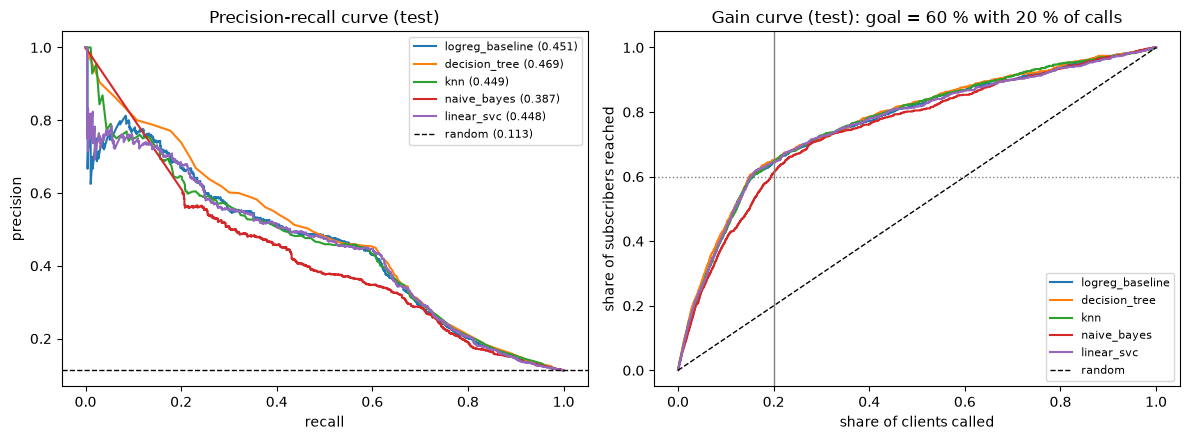

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for n in names:
    if n == "dummy":
        continue
    p, r, _ = precision_recall_curve(y_test, scores[n])
    axes[0].plot(r, p, label=f"{n} ({average_precision_score(y_test, scores[n]):.3f})")
    called, reached = gain_curve(y_test, scores[n])
    axes[1].plot(called, reached, label=n)
axes[0].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"random ({y_test.mean():.3f})")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-recall curve (test)")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[1].axvline(0.2, color="grey", lw=1); axes[1].axhline(0.6, color="grey", lw=1, ls=":")
axes[1].set_xlabel("share of clients called"); axes[1].set_ylabel("share of subscribers reached")
axes[1].set_title("Gain curve (test): goal = 60 % with 20 % of calls")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "test_pr_gain_curves.png", dpi=150); plt.show()

## 4. Robustness: train on the past, test on the most recent calls

In [5]:
old, recent = temporal_split(df)
X_old, y_old = xy(old); X_rec, y_rec = xy(recent)
print("share of yes  old 80 %%: %.3f   recent 20 %%: %.3f" % (y_old.mean(), y_rec.mean()))
rows = []
for n in names:
    m = get_model(n).fit(X_old, y_old)
    sc = score(m, X_rec)
    r = ranking_metrics(y_rec, sc)
    r["pr_auc_over_prevalence"] = r["pr_auc"] / y_rec.mean()   # PR-AUC depends on the share of yes, this makes it comparable
    r["random_split_pr_auc_over_prevalence"] = test_table.loc[n, "pr_auc"] / y_test.mean()
    r["random_split_roc_auc"] = test_table.loc[n, "roc_auc"]
    if hasattr(m, "predict_proba"):
        r["mean_proba"] = sc.mean()
    rows.append({"model": n, **r})
temporal = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)
temporal.to_csv(RESULTS / "temporal_comparison.csv")
temporal

share of yes  old 80 %: 0.064   recent 20 %: 0.308


,pr_auc,roc_auc,recall_top20,pr_auc_over_prevalence,random_split_pr_auc_over_prevalence,random_split_roc_auc,mean_proba
model,,,,,,,
linear_svc,0.5360,0.7518,0.3876,1.7386,3.9790,0.7970,NaN
naive_bayes,0.5393,0.7324,0.3946,1.7494,3.4326,0.7816,0.7836
logreg_baseline,0.5398,0.7045,0.4021,1.7510,4.0032,0.7985,0.1491
knn,0.5218,0.7005,0.4080,1.6926,3.9813,0.8023,0.1483
decision_tree,0.3346,0.5329,0.2220,1.0852,4.1636,0.8054,0.4453
dummy,0.3083,0.5000,0.2001,1.0000,1.0000,0.5000,0.0638


When we train on the past and test on the most recent calls, everything gets worse, and some models break:
* The share of yes goes from 6.4 % in the old data to 30.8 % in the recent data. The PR-AUC values cannot be
  compared directly, so we divide them by the share of yes: the baseline goes from 4.0 times better than random
  (random split) to only 1.75 times. Its ROC-AUC drops from 0.80 to 0.70.
* The recall in the top 20 % falls to about 0.40 (the best possible is 0.65 since there are now more yes than
  20 % of the calls).
* **The decision tree collapses** (ROC-AUC 0.53, almost random). The reason: 99 % of the recent calls have a
  `euribor3m` lower than anything seen in training (0.63-1.30 against 1.30-5.05). A tree cannot extrapolate: all
  these clients fall in the same leaves, 40 % of them get exactly the same score. Linear models extend the trend
  and survive better (linear SVM 0.75, logistic regression 0.70).
* **The probabilities are wrong after the drift:** the baseline predicts on average 0.149 when the real share is
  0.308. A bank using the probabilities directly would underestimate its success rate by half.

This is the main limitation of the project: the random split gives optimistic scores because the
economic variables tell the model *when* the call was made. Random forest and boosting are also made of
trees, so the step 3 models must be checked on this split too.

## 5. Conclusion
* The logistic regression baseline (C = 0.01, no class weight) reaches the goal of step 1: 64 % of the
  subscribers with 20 % of the calls on the test set, AUC 0.80 like the literature.
* The standard algorithms of AutoML v0.1 do not beat it in a significant way (paired bootstrap).
* On the most recent calls all the models lose a lot, the trees the most. Step 3 models have to be judged on
  both splits, and a model that only wins on the random split should not be preferred.
* Step 3 models (random forest, boosting, ensemble, model outside the course) are added to `src/models.py`
  and this notebook is run again: the tables and figures update by themselves.